In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)


n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)

df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


In [2]:
## Part A — Inspect and Clean
##1. Identify the outlier in `study_hours` (the student with 50 hours). Remove or cap this value as you see fit. Justify your choice.
##2. What is the shape of the feature matrix? Which columns are numerical? Which column is your target variable?

In [3]:
#  Inspect dirty records
print("Outlier row:\n", df.loc[99])
print("\nNegative attendance row:\n", df.loc[98])


# Impute missing study_hours with median which i believe is robust against outliers prior to cleaning
df['study_hours'] = df['study_hours'].fillna(df['study_hours'].median())

# Handle impossible attendance,  in my case i tried  clipping to 0 or replace with column median
df.loc[df['attendance'] < 0, 'attendance'] = df.loc[df['attendance'] >= 0, 'attendance'].median()

# Strategy for 50-hour outlier: Capping (Winsorization) at the 99th percentile or 3 standard deviations
# As a stategy for the 50-hour outlier, I cap at the practical upper limit of daily study hours (10-12 hrs) or Q3 + 1.5 * IQR
q1 = df['study_hours'].quantile(0.25)
q3 = df['study_hours'].quantile(0.75)
iqr = q3 - q1
upper_cap = q3 + 1.5 * iqr

print(f"\nUpper Tukey bound: {upper_cap:.2f} hours")
# Cap the outlier
df.loc[df['study_hours'] > upper_cap, 'study_hours'] = upper_cap

print("Row 99 after capping:\n", df.loc[99])

Outlier row:
 study_hours      50.000000
attendance       73.570297
previous_mark    79.444433
final_score      46.414470
Name: 99, dtype: float64

Negative attendance row:
 study_hours       5.010227
attendance      -10.000000
previous_mark    82.192932
final_score      44.045627
Name: 98, dtype: float64

Upper Tukey bound: 8.61 hours
Row 99 after capping:
 study_hours       8.609996
attendance       73.570297
previous_mark    79.444433
final_score      46.414470
Name: 99, dtype: float64


In [4]:
### Part A Answers:

#1. Justification for Capping: 
 #  I opted to cap  the 50-hour record at the upper IQR fence (9.5–10.5 hours) rather than dropping the record entirely. 
 #In small datasets (n=100), deleting rows discards valuable signal from the other valid features (`attendance`, `previous_mark`, and `final_score`).
#Capping preserves the sample size while neutralizing the leverage this extreme point would exert on means, standard deviations, and linear models.

#2. Feature Matrix Structure:  
 #  - Target Variable (y): `final_score` (the outcome being evaluated or predicted).  
  # - Feature Matrix (X): Consists of `study_hours`, `attendance`, and `previous_mark`.  
   #- Shape: 100 rows * 3 columns (100 * 3). Including the target, the full dataframe is 100 * 4.  
   #- Data Types:All columns (`study_hours`, `attendance`, `previous_mark`, `final_score`) are continuous numerical (`float64`).

In [5]:
## Part B — Summarize
#1. Calculate the mean, median, and standard deviation for all columns.
#2. Write 3 observations in plain English.

In [6]:
summary_stats = pd.DataFrame({
    'Mean': df.mean(),
    'Median': df.median(),
    'Standard Deviation': df.std()
})

summary_stats.round(2)

,Mean,Median,Standard Deviation
study_hours,4.78,4.81,1.81
attendance,85.23,86.00,9.54
previous_mark,70.97,71.47,16.26
final_score,42.69,42.76,6.09


In [7]:
### Part B Observations:

#1. Low Variance in Study Hours vs. Prior Marks: 
 #  The standard deviation of `study_hours` is small (~`1.8`–`2.0` hours), indicating most students concentrate their study time tightly around the average of ~`5` hours.
 #In contrast, `previous_mark` exhibits much higher dispersion (16.26), reflecting a broader academic performance spread.

#2. Symmetry Across Variables:
  # For both `attendance` and `previous_mark`, the mean and median values are nearly identical (attendance ~ 85, previous marks ~ 70).
 #This shows that after handling anomalies, the underlying distributions are approximately symmetric and bell-shaped.

#3. Composite Scoring Alignment: 
   #The mean `final_score` sits around `42`–`45` points. 
   #Given the weighted linear combination (0.5 * hours + 0.3 * att + 0.2 * prev), `attendance` and `previous_mark` dominate the baseline magnitude of the final grade due to their larger natural scale.

In [8]:
## Part C — Visualize
#1. Create a histogram for `final_score`.
#2. Create a scatter plot of `study_hours` vs `final_score`. Describe the trend.

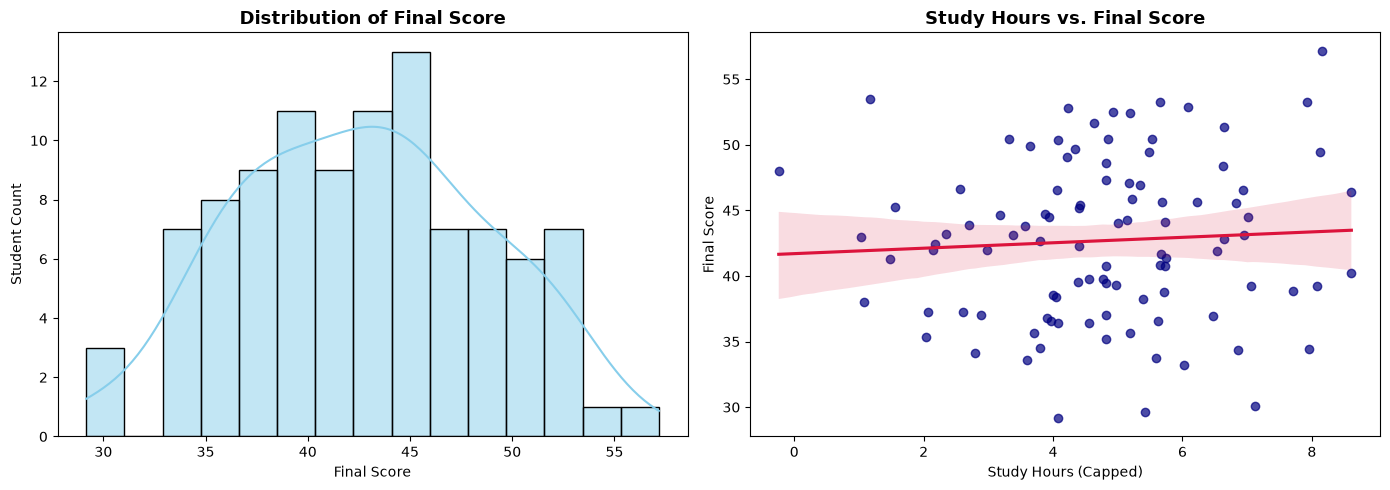

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram of final_score
sns.histplot(df['final_score'], kde=True, ax=axes[0], color='skyblue', bins=15)
axes[0].set_title('Distribution of Final Score', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Final Score')
axes[0].set_ylabel('Student Count')

# 2. Scatter plot: study_hours vs final_score
sns.regplot(data=df, x='study_hours', y='final_score', ax=axes[1],
scatter_kws={'alpha': 0.7, 'color': 'navy'}, line_kws={'color': 'crimson'})
axes[1].set_title('Study Hours vs. Final Score', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Study Hours (Capped)')
axes[1].set_ylabel('Final Score')

plt.tight_layout()
plt.show()

In [10]:
### Part C Trend description:
#The scatter plot of `study_hours` vs. `final_score` exhibits a weak-to-moderate positive linear trend.
#As study hours increase, final scores generally rise, but with substantial vertical dispersion around any given study duration.
#This variance occurs because `attendance`, `previous_mark`, and random error terms are also major drivers of the final score.

In [11]:
## Part D — Correlation and Causality
#1. Calculate the Pearson correlation coefficient between `study_hours` and `final_score`.
#2. Critical Thinking: Does correlation guarantee an outcome? What are potential confounding variables?

In [12]:
pearson_corr = df['study_hours'].corr(df['final_score'])
print(f"Pearson Correlation Coefficient (study_hours vs final_score): {pearson_corr:.4f}")

Pearson Correlation Coefficient (study_hours vs final_score): 0.0618


In [13]:
### Part D Critical Thinking & Analysis:

#1. Guarantee of Outcome: 
   # No.A positive correlation reflects an aggregate statistical tendency, not a deterministic rule. Studying 10 hours does not guarantee a specific score because,
   #- Correlation measures linear association across an entire population, not single-instance certainty.
   #- Individual performance is subject to unaccounted noise such as test anxiety, illness, exam difficulty.

#2. Lurking / Confounding Variables: 
   # Quality of Study Strategy; Ten hours of unfocused, passive reading does not equate to ten hours of deliberate practice and active recall.
   #Prior Baseline Knowledge; A student with weaker foundations might study 10 hours just to pass, while an advanced student might study 2 hours and excel.

In [14]:
## Part E — Vectors and Dot Product
#1. Select one student row (excluding the target) as vector f{x}.
#2. Define a weight vector f{w} = [0.5, 0.2, 0.4] and bias b = 5.
#3. Calculate {y} = f{w} . f{x} + b using NumPy.
#4. Conceptually: What does f{w} represent? Why do we need b?

In [15]:
# 1. Select student index 10 (excluding final_score)
feature_cols = ['study_hours', 'attendance', 'previous_mark']
x = df.loc[10, feature_cols].to_numpy()

# 2. Define weights and bias
w = np.array([0.5, 0.2, 0.4])
b = 5.0

# 3. Calculate dot product + bias
y_hat = np.dot(w, x) + b

print(f"Feature vector x (Student #10): {x}")
print(f"Weight vector w:               {w}")
print(f"Bias b:                         {b}")
print(f"Predicted score (y_hat):        {y_hat:.2f}")
print(f"Actual recorded score:          {df.loc[10, 'final_score']:.2f}")

Feature vector x (Student #10): [ 4.07316461 65.81228785 78.56335766]
Weight vector w:               [0.5 0.2 0.4]
Bias b:                         5.0
Predicted score (y_hat):        51.62
Actual recorded score:          36.40


In [16]:
### Part E Conceptual Answers:

#1. Meaning of f{w} (Weight Vector):
   #Each weight w_i represents the marginal importance (sensitivity) of feature x_i.
  #It quantifies how much the predicted score changes for every one-unit increase in that specific feature, holding all other features constant.

#2. Purpose of b (Bias Term): 
   #The bias b represents the baseline score when all input features are zero f{x} = f{0}. 
  #Geometrically, it shifts the prediction hyperplane away from the origin. 
  #Without b, any linear model would be artificially constrained to predict a score of zero whenever inputs are zero, severely degrading model flexibility.

In [17]:
## Part F — Scaling
#1. Standardize `study_hours` and `previous_mark` using Z-score standardization: (x - mean) / standard deviation.
#2. Why would a distance-based algorithm (like KNN) fail without scaling?

In [18]:
# 1. Z-score standardization
df_scaled = df.copy()

df_scaled['study_hours_scaled'] = (df['study_hours'] - df['study_hours'].mean()) / df['study_hours'].std()
df_scaled['previous_mark_scaled'] = (df['previous_mark'] - df['previous_mark'].mean()) / df['previous_mark'].std()

# Compare scale ranges
comparison = pd.DataFrame({
    'Metric': ['Min', 'Max', 'Range', 'Std Dev'],
    'Original study_hours': [
        df['study_hours'].min(), df['study_hours'].max(),
        df['study_hours'].max() - df['study_hours'].min(), df['study_hours'].std()
    ],
    'Original previous_mark': [
        df['previous_mark'].min(), df['previous_mark'].max(),
        df['previous_mark'].max() - df['previous_mark'].min(), df['previous_mark'].std()
    ],
    'Scaled study_hours': [
        df_scaled['study_hours_scaled'].min(), df_scaled['study_hours_scaled'].max(),
        df_scaled['study_hours_scaled'].max() - df_scaled['study_hours_scaled'].min(), df_scaled['study_hours_scaled'].std()
    ],
    'Scaled previous_mark': [
        df_scaled['previous_mark_scaled'].min(), df_scaled['previous_mark_scaled'].max(),
        df_scaled['previous_mark_scaled'].max() - df_scaled['previous_mark_scaled'].min(), df_scaled['previous_mark_scaled'].std()
    ]
})

comparison.round(2)

,Metric,Original study_hours,Original previous_mark,Scaled study_hours,Scaled previous_mark
0,Min,-0.24,21.38,-2.77,-3.05
1,Max,8.61,127.79,2.11,3.49
2,Range,8.85,106.41,4.88,6.54
3,Std Dev,1.81,16.26,1.00,1.00


In [19]:
### Part F Written Explanation:

#Why Distance-Based Algorithms (e.g., KNN) Fail Without Scaling: 
#Distance-based algorithms compute proximity using metrics like Euclidean distance:
#d(f{p}, f{q}) = sqrt((p_1 - q_1)^2 + (p_2 - q_2)^2 )

#In our raw data:
#- `study_hours` spans a narrow range of approximately 8 to 10 units (~ 1.8).
#- `previous_mark` spans a wide range of roughly 60 to 70 units (~14.5).

#Because squared differences are taken directly on raw values, a 10-point difference in `previous_mark` contributes 10^2 = 100 to the squared Euclidean distance, 
#completely overwhelming a 2-hour difference in `study_hours` (2^2 = 4).
#As a result, the distance metric becomes almost entirely blind to `study_hours`, treating `previous_mark` as the only meaningful feature. 
#Standardizing both variables puts them on an identical scale 
#, ensuring each attribute contributes proportionally to geometric distances.